<a href="https://colab.research.google.com/github/Pappas313/SEObGeoAnal/blob/main/SEObGeoAnal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**1. Project overview**

**Project scenario:** Monitor vegetation health, drought conditions, and land surface changes in Athens, Greece, using Sentinel-2 satellite imagery.

**Technologies and their roles**

**Technology	                   Purpose**

**Collasterio**	                     Name needs clarification; likely a geospatial raster library

**Xarray**	                         Multidimensional satellite datasets

**Dask**	                           Parallel and lazy processing

**Datacube**	                       Satellite data cube concepts and indexing

**PySTAC**                         Satellite imagery metadata and STAC catalogs

**deck.gl / pydeck**	               Interactive geospatial visualization

**Pandas**	                         Tabular environmental analytics

**Seaborn**	                         Statistical visualizations

**Matplotlib**	                     Satellite raster plots

**Plotly**	                         Interactive charts and dashboards

**SciPy**	                           Image filtering, statistics, and scientific calculations

**2. Architecture**

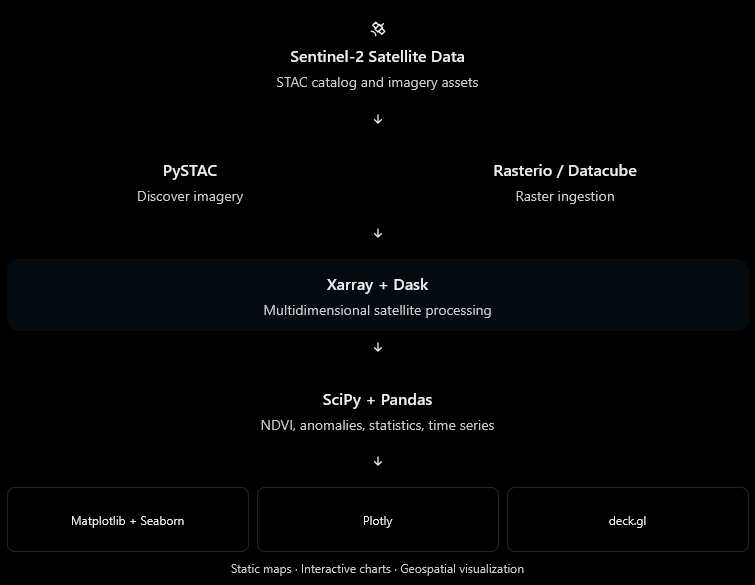

**3. Implementation roadmap — 12 Google Colab stages**

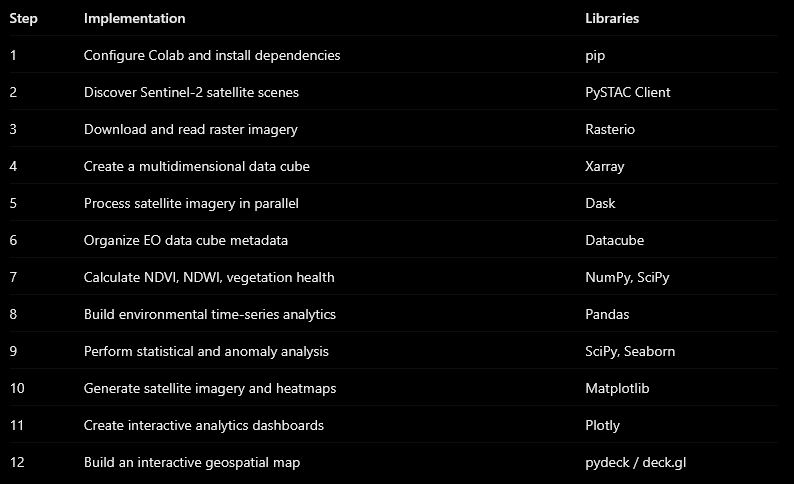

The Open Data Cube library is more demanding to configure than Xarray and Dask, particularly because its full indexed workflow typically uses a database. In Colab, we'll start with an Xarray-based data cube and then introduce Open Data Cube separately.

**4. Start the project in Google Colab**

Below are the first executable notebook cells.

**Step 1 — Install the Python libraries**

In [1]:

%pip -q install rasterio rioxarray xarray "dask[complete]" \
    pystac pystac-client planetary-computer stackstac \
    pandas seaborn matplotlib plotly scipy pydeck \
    odc-stac


I have assumed you meant Rasterio by "collasterio." If you meant a different library, tell me its exact name. We'll use odc-stac for Colab-friendly data cube loading, with the full datacube package as an optional advanced extension.

**Step 2 — Import dependencies**

In [2]:

import numpy as np
import pandas as pd
import xarray as xr
import dask.array as da

import rasterio
import rioxarray
import pystac_client
import planetary_computer
import stackstac
import odc.stac

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import pydeck as pdk

from scipy import stats, ndimage

print("Satellite Analytics environment ready!")


Satellite Analytics environment ready!


**Step 3 — Connect to the satellite catalog**

We'll use the Microsoft Planetary Computer STAC API to discover real Sentinel-2 satellite observations.

In [3]:

catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace
)

# Athens, Greece — small bounding box
bbox = [23.65, 37.93, 23.85, 38.08]

search = catalog.search(
    collections=["sentinel-2-l2a"],
    bbox=bbox,
    datetime="2025-06-01/2025-08-31",
    query={"eo:cloud_cover": {"lt": 15}},
    max_items=10
)

items = list(search.items())

print(f"Found {len(items)} satellite scenes")

for item in items[:5]:
    print(
        item.id,
        item.datetime,
        item.properties.get("eo:cloud_cover")
    )


Found 10 satellite scenes
S2B_MSIL2A_20250827T090559_R050_T35SKC_20250827T101153 2025-08-27 09:05:59.024000+00:00 5.644762
S2B_MSIL2A_20250827T090559_R050_T34SGH_20250827T101153 2025-08-27 09:05:59.024000+00:00 7.087664
S2A_MSIL2A_20250824T091321_R050_T35SKC_20250824T113416 2025-08-24 09:13:21.024000+00:00 9.369797
S2A_MSIL2A_20250824T091321_R050_T34SGH_20250824T113416 2025-08-24 09:13:21.024000+00:00 9.296734
S2C_MSIL2A_20250822T090611_R050_T35SKC_20250822T131014 2025-08-22 09:06:11.025000+00:00 0.003358


**Step 4 — Build an Xarray satellite data cube**

In [4]:

if not items:
    raise ValueError("No satellite scenes found. Expand the date range.")

cube = odc.stac.load(
    items,
    bands=["B02", "B03", "B04", "B08"],
    bbox=bbox,
    resolution=100,
    groupby="solar_day",
    chunks={"time": 1, "x": 512, "y": 512}
)

print(cube)


<xarray.Dataset> Size: 3MB
Dimensions:      (y: 173, x: 183, time: 5)
Coordinates:
  * y            (y) float64 1kB 4.22e+06 4.22e+06 ... 4.203e+06 4.203e+06
  * x            (x) float64 1kB 2.056e+05 2.056e+05 ... 2.236e+05 2.238e+05
  * time         (time) datetime64[ns] 40B 2025-08-12T09:06:11.025000 ... 202...
    spatial_ref  int32 4B 32635
Data variables:
    B02          (time, y, x) float32 633kB dask.array<chunksize=(1, 173, 183), meta=np.ndarray>
    B03          (time, y, x) float32 633kB dask.array<chunksize=(1, 173, 183), meta=np.ndarray>
    B04          (time, y, x) float32 633kB dask.array<chunksize=(1, 173, 183), meta=np.ndarray>
    B08          (time, y, x) float32 633kB dask.array<chunksize=(1, 173, 183), meta=np.ndarray>


Here, resolution=100 means 100-meter pixels, which keeps memory usage manageable in Colab. Dask processes the data lazily.

**Step 5 — Calculate NDVI**

The Normalized Difference Vegetation Index measures vegetation greenness using the red and near-infrared spectral bands.
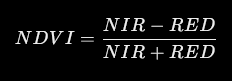

/usr/local/lib/python3.13/dist-packages/rasterio/warp.py:390: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dest = _reproject(


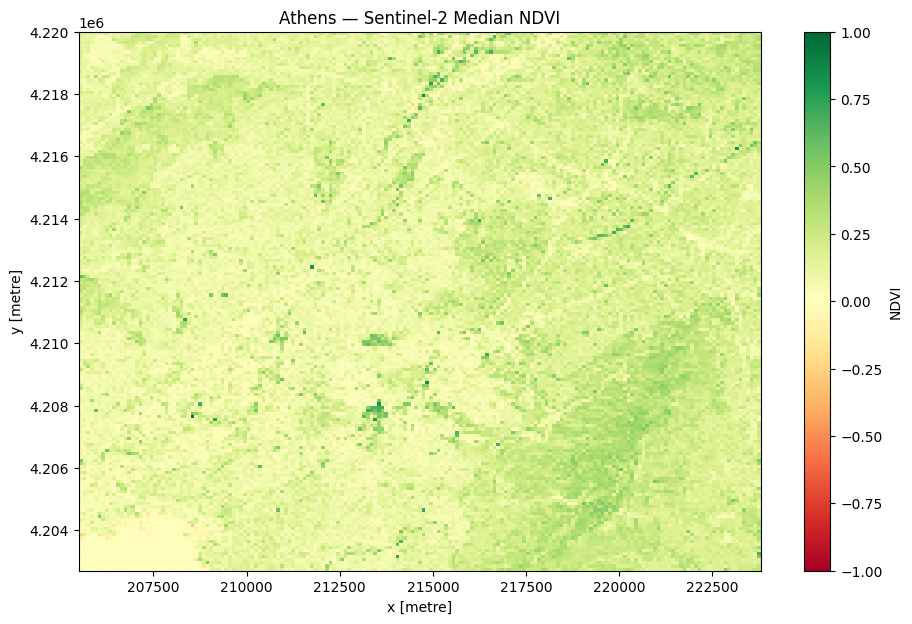

In [5]:

red = cube["B04"].astype("float32")
nir = cube["B08"].astype("float32")

denominator = nir + red

ndvi = xr.where(
    denominator > 0,
    (nir - red) / denominator,
    np.nan
).where((red > 0) & (nir > 0))

ndvi = ndvi.clip(-1, 1)
ndvi.name = "NDVI"

# Compute the temporal median
median_ndvi = ndvi.median(dim="time").compute()

plt.figure(figsize=(11, 7))
median_ndvi.plot(
    cmap="RdYlGn",
    vmin=-1,
    vmax=1
)
plt.title("Athens — Sentinel-2 Median NDVI")
plt.show()


**Step 6 - Imports and output directory**

In [6]:
import os, numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt, seaborn as sns, plotly.graph_objects as go
import pydeck as pdk
from scipy import ndimage, stats
from pystac_client import Client
import planetary_computer
from odc.stac import load
from pathlib import Path
from IPython.display import display, HTML
OUT = Path('/content/sateo_outputs') if Path('/content').exists() else Path('sateo_outputs')
OUT.mkdir(parents=True, exist_ok=True)
BBOX = (23.65, 37.93, 23.85, 38.08)
print('Output directory:', OUT)

Output directory: /content/sateo_outputs


**Step 7 — Search STAC for real satellite scenes**

Scenes are selected across several months to provide a meaningful time series. STAC search is remote and requires an internet connection.

In [7]:
catalog = Client.open('https://planetarycomputer.microsoft.com/api/stac/v1', modifier=planetary_computer.sign_inplace)
search = catalog.search(collections=['sentinel-2-l2a'], bbox=BBOX, datetime='2025-04-01/2025-10-31', query={'eo:cloud_cover': {'lt': 30}}, max_items=120)
all_items = sorted(list(search.items()), key=lambda item: item.datetime)
# Limit to one least-cloudy item per calendar month to bound Colab memory and processing time.
by_month = {}
for item in all_items:
    month = item.datetime.strftime('%Y-%m')
    if month not in by_month or item.properties.get('eo:cloud_cover', 100) < by_month[month].properties.get('eo:cloud_cover', 100):
        by_month[month] = item
items = sorted(by_month.values(), key=lambda item: item.datetime)
if len(items) < 2:
    raise RuntimeError('Fewer than two scenes found. Expand date range or cloud-cover threshold.')
print('Scenes selected:', len(items))
for item in items: print(item.datetime.date(), item.properties.get('eo:cloud_cover'))

Scenes selected: 7
2025-04-06 7.156526
2025-05-26 0.644875
2025-06-25 0.008291
2025-07-23 0.00508
2025-08-22 0.003358
2025-09-11 0.003759
2025-10-11 6.944612


**Step 8 — Load data cube with Dask and mask clouds**

Sentinel-2 L2A bands are stored as scaled integers. We convert to reflectance by dividing by 10,000; the common offset is immaterial to this illustrative workflow but processing-baseline changes may require the appropriate harmonization for rigorous time-series analysis. SCL classes 4/5/6/7 are used here; class 7 is unclassified and is excluded for a more conservative mask.

In [8]:
cube = load(items, bands=['B03','B04','B08','SCL'], bbox=BBOX, resolution=100, groupby='solar_day', chunks={'time':1, 'y':512, 'x':512})
valid = cube.SCL.isin([4,5,6])
green = (cube.B03.astype('float32') / 10000).where(valid)
red = (cube.B04.astype('float32') / 10000).where(valid)
nir = (cube.B08.astype('float32') / 10000).where(valid)
ndvi = xr.where((nir+red)>0, (nir-red)/(nir+red), np.nan).clip(-1,1).rename('NDVI')
ndwi = xr.where((green+nir)>0, (green-nir)/(green+nir), np.nan).clip(-1,1).rename('NDWI')
# Calculate arrays once; scenes are small because of the 100 m resolution.
ndvi = ndvi.compute(); ndwi = ndwi.compute()
print('NDVI cube:', ndvi.shape, 'NDWI cube:', ndwi.shape)

NDVI cube: (7, 173, 183) NDWI cube: (7, 173, 183)


**Step 9 — Image 1: Vegetation health map (PNG)**

The map shows median NDVI across the selected cloud-masked scenes. Median filtering reduces isolated pixel noise.

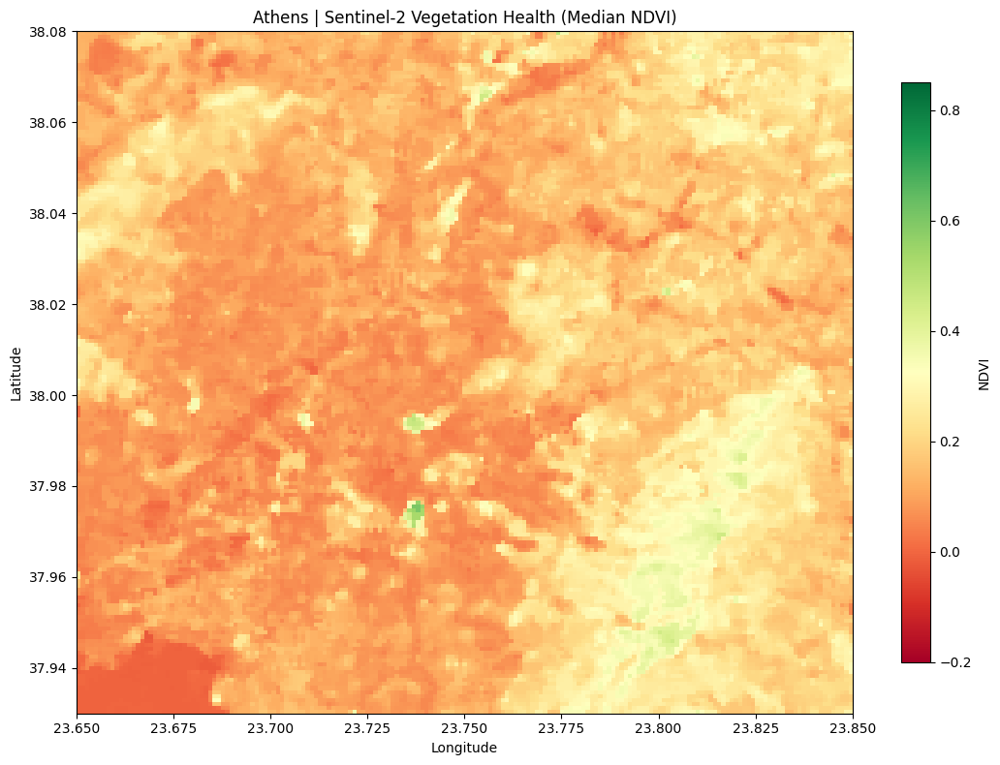

In [9]:
median = ndvi.median('time', skipna=True)
a = median.values
smoothed = ndimage.median_filter(np.nan_to_num(a, nan=-1), size=3)
smoothed[np.isnan(a)] = np.nan
fig, ax = plt.subplots(figsize=(11,8))
im = ax.imshow(smoothed, cmap='RdYlGn', vmin=-0.2, vmax=0.85, origin='upper', extent=[BBOX[0],BBOX[2],BBOX[1],BBOX[3]], aspect='auto')
ax.set(title='Athens | Sentinel-2 Vegetation Health (Median NDVI)', xlabel='Longitude', ylabel='Latitude')
fig.colorbar(im, ax=ax, label='NDVI', shrink=.85)
fig.tight_layout(); fig.savefig(OUT/'vegetation_health.png', dpi=180); plt.show()

**Step 10 — Environmental summary**

These are vegetation/water indices derived from satellite reflectance, not measured CO₂, temperature, or precipitation. Environmental charts use the spatial average per observation date.

In [10]:
summary = pd.DataFrame({'date':pd.to_datetime(ndvi.time.values), 'mean_ndvi':ndvi.mean(('x','y'), skipna=True).values, 'mean_ndwi':ndwi.mean(('x','y'), skipna=True).values, 'vegetation_fraction':(ndvi>0.3).mean(('x','y')).values})
summary = summary.dropna().sort_values('date')
summary['vegetation_pct'] = 100*summary['vegetation_fraction']
summary.to_csv(OUT/'environmental_timeseries.csv', index=False)
display(summary)

,date,mean_ndvi,mean_ndwi,vegetation_fraction,vegetation_pct
0,2025-04-06 09:13:21.024,0.184287,-0.209201,0.156575,15.657475
1,2025-05-26 09:10:41.024,0.173164,-0.212958,0.121482,12.148204
2,2025-06-25 09:13:31.024,0.158356,-0.204716,0.081367,8.136707
3,2025-07-23 09:06:21.025,0.154212,-0.207267,0.093244,9.324363
4,2025-08-22 09:06:11.025,0.159009,-0.214004,0.095044,9.504406
5,2025-09-11 09:06:11.025,0.147351,-0.196211,0.079946,7.994567
6,2025-10-11 09:09:31.025,0.162213,-0.198730,0.112354,11.235352


**Step 11 — Image 2: Environmental dashboard (interactive HTML + PNG if Kaleido works)**

In [11]:
from plotly.subplots import make_subplots
fig = make_subplots(rows=2, cols=2, subplot_titles=['Mean NDVI','Mean NDWI','Vegetated area (%)','NDVI vs NDWI'], vertical_spacing=.17)
fig.add_trace(go.Scatter(x=summary.date,y=summary.mean_ndvi,mode='lines+markers',name='NDVI'),1,1)
fig.add_trace(go.Scatter(x=summary.date,y=summary.mean_ndwi,mode='lines+markers',name='NDWI'),1,2)
fig.add_trace(go.Bar(x=summary.date,y=summary.vegetation_pct,name='Vegetated %'),2,1)
fig.add_trace(go.Scatter(x=summary.mean_ndvi,y=summary.mean_ndwi,mode='markers+text',text=summary.date.dt.strftime('%b'),textposition='top center',name='Dates'),2,2)
fig.update_layout(title='Athens | Satellite Environmental Analytics',template='plotly_dark',height=760,showlegend=False)
fig.update_xaxes(title_text='Mean NDVI',row=2,col=2);fig.update_yaxes(title_text='Mean NDWI',row=2,col=2)
fig.write_html(str(OUT/'environmental_dashboard.html'), include_plotlyjs=True)
try:
    fig.write_image(str(OUT/'environmental_dashboard.png'),width=1400,height=900,scale=1.5)
    print('Saved dashboard PNG')
except Exception as e:
    print('PNG export unavailable in this runtime (HTML is saved):',str(e)[:200])
fig.show()

PNG export unavailable in this runtime (HTML is saved): 
Image export using the "kaleido" engine requires the kaleido package,
which can be installed using pip:
    $ pip install -U kaleido



**Step 12 — Image 3: Statistical correlation heatmap (PNG)**

Correlation is computed across observation dates. With only a few scenes, estimates can be unstable; interpret them descriptively rather than causally.

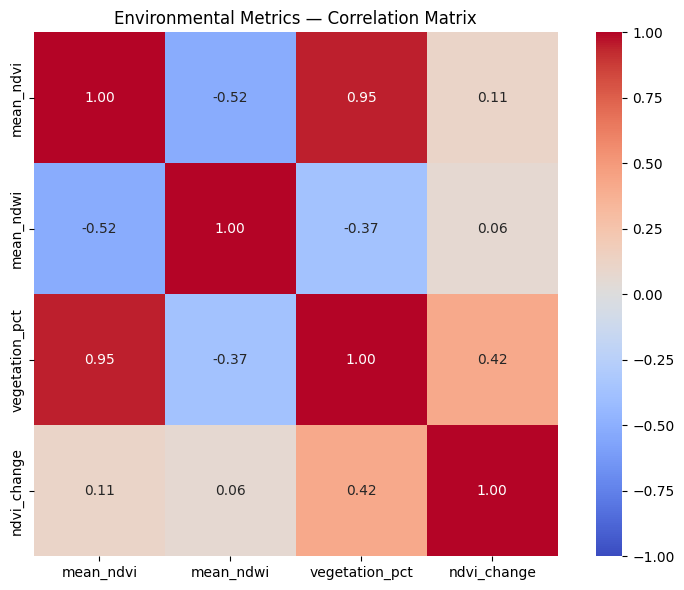

Pearson r=0.949, p=0.0011 (small-sample caution)


In [12]:
features = summary[['mean_ndvi','mean_ndwi','vegetation_pct']].copy()
features['ndvi_change'] = features.mean_ndvi.diff()
corr = features.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(8,6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title('Environmental Metrics — Correlation Matrix')
fig.tight_layout();fig.savefig(OUT/'correlation_heatmap.png',dpi=180);plt.show()
# Example SciPy statistic: correlation between NDVI and vegetation fraction
if len(summary)>=3:
    r,p=stats.pearsonr(summary.mean_ndvi,summary.vegetation_pct)
    print(f'Pearson r={r:.3f}, p={p:.3g} (small-sample caution)')

**Step 13 — Image 4: Interactive 3D geospatial map (deck.gl / pydeck)**

A grid of 3D columns visualizes local median NDVI. Heights are an illustrative transformation of NDVI and do not represent real elevation or building height. Use the saved HTML to interact with the map.

In [13]:
# Spatially aggregate the raster into a small number of cells for fast WebGL rendering.
arr = median.values
ys = np.asarray(median.y.values); xs = np.asarray(median.x.values)
# odc.stac typically returns projected x/y coordinates; reproject to WGS84 via rasterio.
from rasterio.warp import transform as warp_transform
records=[]
step=4
for i in range(0,len(ys),step):
    for j in range(0,len(xs),step):
        block=arr[i:i+step,j:j+step]
        if not np.isfinite(block).any(): continue
        value=float(np.nanmean(block))
        lon,lat=warp_transform(str(median.odc.crs),'EPSG:4326',[float(xs[min(j+step//2,len(xs)-1)])],[float(ys[min(i+step//2,len(ys)-1)])])
        records.append({'longitude':lon[0],'latitude':lat[0],'ndvi':round(value,3),'height':max(10,(value+0.2)*350),'color':[int(230*(1-max(0,value))),int(80+160*max(0,value)),55,210]})
geo=pd.DataFrame(records)
if geo.empty: raise RuntimeError('No valid NDVI pixels available for 3D map')
geo.to_csv(OUT/'geospatial_grid.csv',index=False)
layer=pdk.Layer('ColumnLayer',data=geo,get_position='[longitude, latitude]',get_elevation='height',elevation_scale=1,radius=300,get_fill_color='color',pickable=True,auto_highlight=True,extruded=True)
view=pdk.ViewState(latitude=float(geo.latitude.mean()),longitude=float(geo.longitude.mean()),zoom=10.4,pitch=48,bearing=15)
deck=pdk.Deck(layers=[layer],initial_view_state=view,tooltip={'html':'<b>NDVI:</b> {ndvi}<br/><b>Illustrative column height:</b> {height}','style':{'color':'white'}},map_style='light')
deck.to_html(str(OUT/'geospatial_3d_map.html'), notebook_display=False)
display(deck)
print('Interactive map saved:',OUT/'geospatial_3d_map.html')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

{
  "initialViewState": {
    "bearing": 15,
    "latitude": 38.00320538785132,
    "longitude": 23.751323007493653,
    "pitch": 48,
    "zoom": 10.4
  },
  "layers": [
    {
      "@@type": "ColumnLayer",
      "autoHighlight": true,
      "data": [
        {
          "color": [
            201,
            99,
            55,
            210
          ],
          "height": 113.0458314716816,
          "latitude": 38.07768285491834,
          "longitude": 23.645451900457168,
          "ndvi": 0.123
        },
        {
          "color": [
            214,
            90,
            55,
            210
          ],
          "height": 93.83644916117191,
          "latitude": 38.07781286729813,
          "longitude": 23.6500048428291,
          "ndvi": 0.068
        },
        {
          "color": [
            198,
            102,
            55,
            210
          ],
          "height": 118.6468181014061,
          "latitude": 38.07794270367134,
          "longitude": 23.65455781448906,
          "ndvi": 0.139
        },
        {
          "color": [
            181,
            113,
            55,
            210
          ],
          "height": 143.62745702266693,
          "latitude": 38.07807236403457,
          "longitude": 23.65911081539756,
          "ndvi": 0.21
        },
        {
          "color": [
            180,
            114,
            55,
            210
          ],
          "height": 144.57692176103592,
          "latitude": 38.078201848384296,
          "longitude": 23.66366384551513,
          "ndvi": 0.213
        },
        {
          "color": [
            186,
            110,
            55,
            210
          ],
          "height": 135.98636507987976,
          "latitude": 38.0783311567171,
          "longitude": 23.668216904802296,
          "ndvi": 0.189
        },
        {
          "color": [
            187,
            109,
            55,
            210
          ],
          "height": 134.51844200491905,
          "latitude": 38.07846028902952,
          "longitude": 23.672769993219575,
          "ndvi": 0.184
        },
        {
          "color": [
            207,
            95,
            55,
            210
          ],
          "height": 104.53427776694298,
          "latitude": 38.07858924531812,
          "longitude": 23.677323110727485,
          "ndvi": 0.099
        },
        {
          "color": [
            195,
            104,
            55,
            210
          ],
          "height": 123.04045379161835,
          "latitude": 38.07871802557945,
          "longitude": 23.681876257286543,
          "ndvi": 0.152
        },
        {
          "color": [
            188,
            108,
            55,
            210
          ],
          "height": 133.00455033779144,
          "latitude": 38.07884662981006,
          "longitude": 23.686429432857267,
          "ndvi": 0.18
        },
        {
          "color": [
            195,
            103,
            55,
            210
          ],
          "height": 121.8723800778389,
          "latitude": 38.07897505800654,
          "longitude": 23.69098263740017,
          "ndvi": 0.148
        },
        {
          "color": [
            202,
            99,
            55,
            210
          ],
          "height": 111.95034056901932,
          "latitude": 38.07910331016544,
          "longitude": 23.69553587087577,
          "ndvi": 0.12
        },
        {
          "color": [
            196,
            103,
            55,
            210
          ],
          "height": 120.74317157268524,
          "latitude": 38.079231386283354,
          "longitude": 23.700089133244568,
          "ndvi": 0.145
        },
        {
          "color": [
            202,
            99,
            55,
            210
          ],
          "height": 111.75594672560692,
          "latitude": 38.079359286356855,
          "longitude": 23.704642424467085,
          "ndvi": 0.119
        },

Interactive map saved: /content/sateo_outputs/geospatial_3d_map.html


**Step 14 — Satellite data acquisition**

Install all required libraries
Create a new notebook at Google Colab and execute: **bold text**

In [16]:

%pip install -q \
    numpy pandas scipy \
    xarray "dask[complete]" \
    rasterio rioxarray \
    pystac pystac-client \
    planetary-computer odc-stac \
    matplotlib seaborn plotly \
    pydeck geopandas shapely \
    scikit-learn


**Import Python libraries**

In [17]:

import os
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import dask.array as da

import rasterio
import rioxarray
import pystac_client
import planetary_computer
import odc.stac

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import pydeck as pdk

from scipy import stats, ndimage
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

from IPython.display import display, HTML

sns.set_theme(style="whitegrid")

OUTPUT = Path("/content/sateo_outputs")
OUTPUT.mkdir(parents=True, exist_ok=True)

print("All libraries imported successfully.")


All libraries imported successfully.


**Connect to the STAC catalog**

In [18]:

catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace
)

print("Connected to Planetary Computer STAC API")


Connected to Planetary Computer STAC API


**Search for Sentinel-2 imagery**

In [21]:
# Define the missing PROJECT configuration dictionary
PROJECT = {
    'start_date': '2025-04-01',
    'end_date': '2025-10-31',
    'max_cloud': 30
}

search = catalog.search(
    collections=["sentinel-2-l2a"],
    bbox=BBOX,
    datetime=(
        f"{PROJECT['start_date']}/"
        f"{PROJECT['end_date']}"
    ),
    query={
        "eo:cloud_cover": {
            "lt": PROJECT["max_cloud"]
        }
    },
    max_items=20
)

items = sorted(
    list(search.items()),
    key=lambda item: item.datetime
)

print(f"Found {len(items)} scenes")

for item in items:
    print(
        item.datetime.date(),
        item.properties.get("eo:cloud_cover")
    )

Found 20 scenes
2025-09-01 0.287448
2025-09-03 0.014761
2025-09-03 0.014728
2025-09-06 3.644583
2025-09-06 2.297418
2025-09-11 0.003759
2025-09-11 0.006669
2025-09-13 6.73518
2025-09-13 7.165673
2025-09-16 0.162534
2025-09-16 0.178689
2025-09-21 20.565997
2025-09-21 18.611845
2025-09-23 1.80575
2025-09-23 1.389634
2025-10-01 29.267046
2025-10-03 14.437675
2025-10-03 15.842077
2025-10-11 6.944612
2025-10-11 10.34205


**Create the Xarray/Dask data cube**

In [22]:
if not items:
    raise RuntimeError(
        "No satellite imagery found. "
        "Increase cloud threshold or date range."
    )

# Add the missing resolution key to the PROJECT dictionary
PROJECT["resolution"] = 100

cube = odc.stac.load(
    items,
    bands=[
        "B02",  # Blue
        "B03",  # Green
        "B04",  # Red
        "B08",  # Near infrared
        "B11",  # Shortwave infrared
        "SCL"   # Scene classification
    ],
    bbox=BBOX,
    resolution=PROJECT["resolution"],
    groupby="solar_day",
    chunks={
        "time": 1,
        "x": 512,
        "y": 512
    }
)

print(cube)

<xarray.Dataset> Size: 8MB
Dimensions:      (y: 173, x: 183, time: 11)
Coordinates:
  * y            (y) float64 1kB 4.22e+06 4.22e+06 ... 4.203e+06 4.203e+06
  * x            (x) float64 1kB 2.056e+05 2.056e+05 ... 2.236e+05 2.238e+05
  * time         (time) datetime64[ns] 88B 2025-09-01T09:06:11.025000 ... 202...
    spatial_ref  int32 4B 32635
Data variables:
    B02          (time, y, x) float32 1MB dask.array<chunksize=(1, 173, 183), meta=np.ndarray>
    B03          (time, y, x) float32 1MB dask.array<chunksize=(1, 173, 183), meta=np.ndarray>
    B04          (time, y, x) float32 1MB dask.array<chunksize=(1, 173, 183), meta=np.ndarray>
    B08          (time, y, x) float32 1MB dask.array<chunksize=(1, 173, 183), meta=np.ndarray>
    B11          (time, y, x) float32 1MB dask.array<chunksize=(1, 173, 183), meta=np.ndarray>
    SCL          (time, y, x) float32 1MB dask.array<chunksize=(1, 173, 183), meta=np.ndarray>


The result is a multidimensional Xarray dataset with time, y, and x dimensions, backed by lazy Dask arrays.

**Mask clouds and invalid pixels**

In [23]:

# SCL classes:
# 4 = vegetation
# 5 = bare soil
# 6 = water
# 7 = unclassified

valid = cube["SCL"].isin([4, 5, 6, 7])

bands = {}

for band in ["B02", "B03", "B04", "B08", "B11"]:
    bands[band] = cube[band].where(valid).astype("float32")

clean = xr.Dataset(bands)

print("Cloud masking configured")


Cloud masking configured


This is a basic Scene Classification Layer mask. For production-level analysis, you can add cloud probability, cloud-shadow buffering, and quality checks.

**Step 15 — Spectral index calculations**

**Calculate NDVI, NDWI, and NDBI**

In [24]:

def normalized_difference(a, b):
    denominator = a + b

    return xr.where(
        denominator != 0,
        (a - b) / denominator,
        np.nan
    ).clip(-1, 1)


ndvi = normalized_difference(
    clean["B08"],
    clean["B04"]
)

ndwi = normalized_difference(
    clean["B03"],
    clean["B08"]
)

ndbi = normalized_difference(
    clean["B11"],
    clean["B08"]
)

indices = xr.Dataset({
    "NDVI": ndvi,
    "NDWI": ndwi,
    "NDBI": ndbi
})

print(indices)


<xarray.Dataset> Size: 4MB
Dimensions:      (y: 173, x: 183, time: 11)
Coordinates:
  * y            (y) float64 1kB 4.22e+06 4.22e+06 ... 4.203e+06 4.203e+06
  * x            (x) float64 1kB 2.056e+05 2.056e+05 ... 2.236e+05 2.238e+05
  * time         (time) datetime64[ns] 88B 2025-09-01T09:06:11.025000 ... 202...
    spatial_ref  int32 4B 32635
Data variables:
    NDVI         (time, y, x) float32 1MB dask.array<chunksize=(1, 173, 183), meta=np.ndarray>
    NDWI         (time, y, x) float32 1MB dask.array<chunksize=(1, 173, 183), meta=np.ndarray>
    NDBI         (time, y, x) float32 1MB dask.array<chunksize=(1, 173, 183), meta=np.ndarray>


**Index	Measurement**

**NDVI**	Vegetation greenness

**NDWI**	Surface water indication

**NDBI**	Built-up surface indication


**Calculate temporal composites**

In [25]:

composites = indices.median(
    dim="time",
    skipna=True
).compute()

rgb = clean[
    ["B04", "B03", "B02"]
].median(
    dim="time",
    skipna=True
).compute()

print("Temporal composites ready")


Temporal composites ready


**Step 16 — Satellite image visualizations**

**Visualization 1 — Vegetation health map**

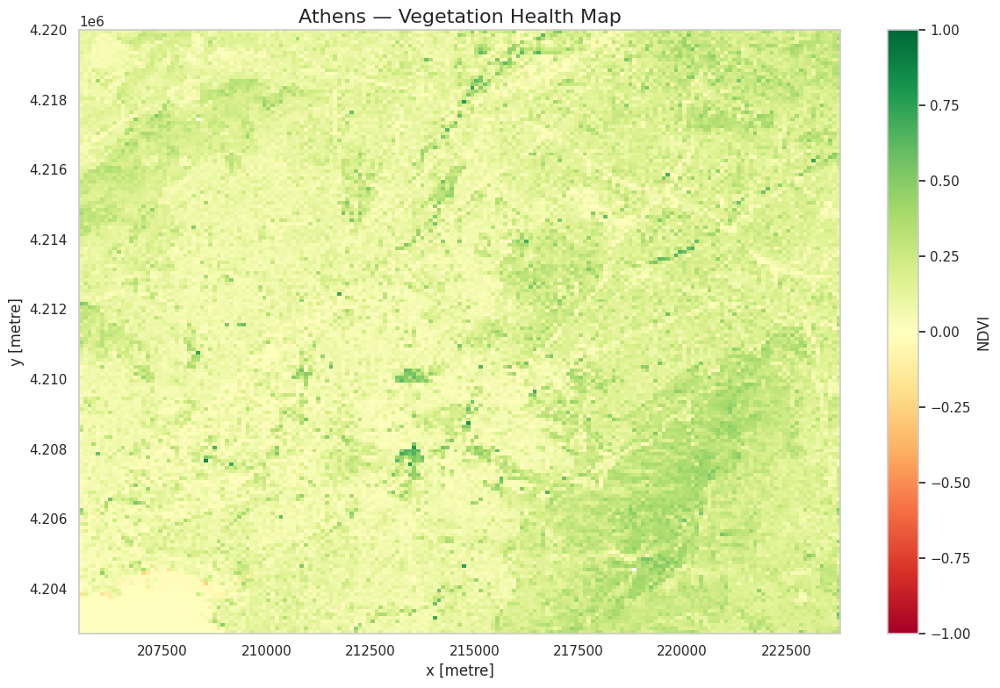

In [26]:

fig, ax = plt.subplots(figsize=(12, 8))

composites["NDVI"].plot(
    ax=ax,
    cmap="RdYlGn",
    vmin=-1,
    vmax=1,
    cbar_kwargs={"label": "NDVI"}
)

ax.set_title(
    "Athens — Vegetation Health Map",
    fontsize=16
)

plt.tight_layout()
plt.savefig(
    OUTPUT / "01_vegetation_health.png",
    dpi=200
)
plt.show()


**Expected result:** A satellite-derived heatmap with green areas representing higher vegetation greenness and red areas representing lower NDVI.

**Visualization 2 — Environmental analytics dashboard**

First, create a regional time series.

In [27]:

ts = indices.mean(
    dim=["x", "y"],
    skipna=True
).compute().to_dataframe().reset_index()

ts["time"] = pd.to_datetime(ts["time"])

print(ts.head())


                     time  spatial_ref      NDVI      NDWI      NDBI
0 2025-09-01 09:06:11.025        32635  0.150164 -0.195819  0.012361
1 2025-09-03 09:10:41.024        32635  0.154518 -0.204739  0.016195
2 2025-09-06 09:05:49.024        32635  0.154785 -0.199405  0.012734
3 2025-09-11 09:06:11.025        32635  0.148040 -0.197456  0.020368
4 2025-09-13 09:13:21.024        32635  0.150775 -0.200094  0.019153


**Now create an interactive dashboard.**

In [28]:

from plotly.subplots import make_subplots

fig = make_subplots(
    rows=3,
    cols=1,
    shared_xaxes=True,
    subplot_titles=[
        "Vegetation Index (NDVI)",
        "Water Index (NDWI)",
        "Built-up Index (NDBI)"
    ]
)

for row, (column, color) in enumerate(
    [
        ("NDVI", "green"),
        ("NDWI", "blue"),
        ("NDBI", "orange")
    ],
    start=1
):
    fig.add_trace(
        go.Scatter(
            x=ts["time"],
            y=ts[column],
            mode="lines+markers",
            name=column,
            line=dict(color=color)
        ),
        row=row,
        col=1
    )

fig.update_layout(
    title="Athens Environmental Monitoring Dashboard",
    height=850,
    template="plotly_dark"
)

fig.show()

fig.write_html(
    str(OUTPUT / "02_environment_dashboard.html")
)


**Expected result:** Three interactive time-series charts showing how vegetation, water-related spectral signals, and built-up indices change over the selected dates.

**Visualization 3 — Statistical correlation heatmap**

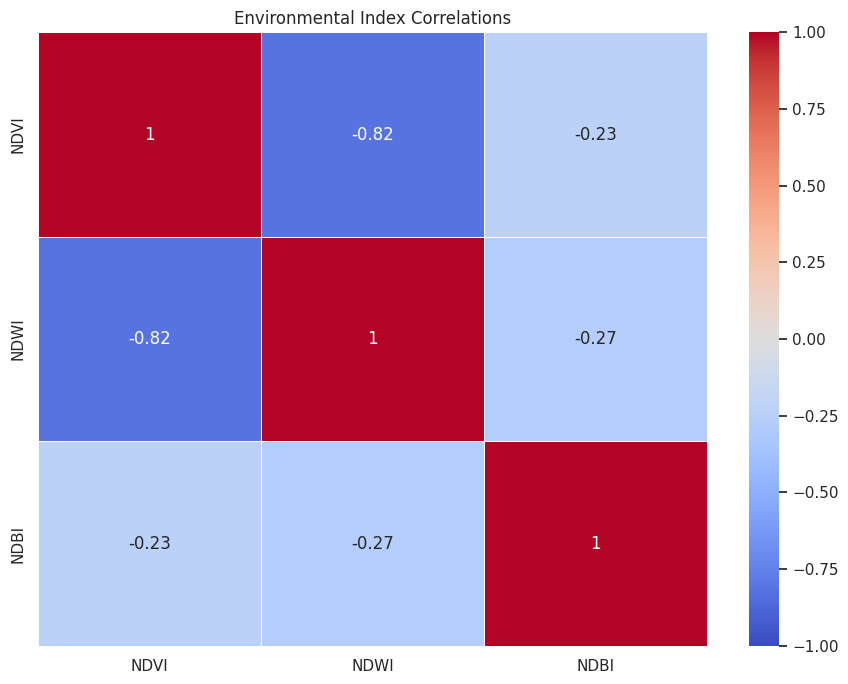

In [29]:

correlation = ts[
    ["NDVI", "NDWI", "NDBI"]
].corr()

plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title("Environmental Index Correlations")

plt.tight_layout()
plt.savefig(
    OUTPUT / "03_correlation_heatmap.png",
    dpi=200
)
plt.show()


This reveals statistical relationships between the environmental indices across the available satellite observations.

**Visualization 4 — Interactive 3D geospatial map**

For this map, convert the satellite raster into geographic point coordinates.

In [30]:

from rasterio.warp import transform

ndvi_map = composites["NDVI"]

# Sample the raster to keep the interactive map responsive
sampled = ndvi_map.isel(
    x=slice(None, None, 3),
    y=slice(None, None, 3)
)

xx, yy = np.meshgrid(
    sampled.x.values,
    sampled.y.values
)

values = sampled.values.ravel()

valid_pixels = np.isfinite(values)

xs = xx.ravel()[valid_pixels]
ys = yy.ravel()[valid_pixels]
values = values[valid_pixels]

crs = str(cube.odc.crs)

longitudes, latitudes = transform(
    crs,
    "EPSG:4326",
    xs.tolist(),
    ys.tolist()
)

geo_df = pd.DataFrame({
    "longitude": longitudes,
    "latitude": latitudes,
    "NDVI": values
})

geo_df["height"] = (
    (geo_df["NDVI"] + 1) * 250
).clip(lower=0)

geo_df["color"] = geo_df["NDVI"].apply(
    lambda v: (
        [30, 180, 80, 190] if v > 0.4
        else [240, 190, 40, 190] if v > 0.2
        else [210, 65, 50, 190]
    )
)

print(geo_df.head())


   longitude   latitude      NDVI      height               color
0  23.643093  38.079417  0.113459  278.364868  [210, 65, 50, 190]
1  23.646508  38.079515  0.128417  282.104309  [210, 65, 50, 190]
2  23.649923  38.079612  0.147071  286.767731  [210, 65, 50, 190]
3  23.653337  38.079710  0.103291  275.822754  [210, 65, 50, 190]
4  23.656752  38.079807  0.105704  276.426086  [210, 65, 50, 190]


**Now generate the 3D map.**

In [31]:

layer = pdk.Layer(
    "ColumnLayer",
    data=geo_df,
    get_position="[longitude, latitude]",
    get_elevation="height",
    elevation_scale=1,
    radius=120,
    get_fill_color="color",
    pickable=True,
    extruded=True
)

view = pdk.ViewState(
    latitude=38.005,
    longitude=23.75,
    zoom=10,
    pitch=55,
    bearing=20
)

deck = pdk.Deck(
    layers=[layer],
    initial_view_state=view,
    tooltip={
        "html": "NDVI: {NDVI}",
        "style": {"color": "white"}
    },
    map_style=None
)

display(deck)

deck.to_html(
    str(OUTPUT / "04_geospatial_3d.html"),
    notebook_display=False
)


<IPython.core.display.Javascript object>

{
  "initialViewState": {
    "bearing": 20,
    "latitude": 38.005,
    "longitude": 23.75,
    "pitch": 55,
    "zoom": 10
  },
  "layers": [
    {
      "@@type": "ColumnLayer",
      "data": [
        {
          "NDVI": 0.11345948278903961,
          "color": [
            210,
            65,
            50,
            190
          ],
          "height": 278.3648681640625,
          "latitude": 38.079417237780504,
          "longitude": 23.643093087184745
        },
        {
          "NDVI": 0.1284172534942627,
          "color": [
            210,
            65,
            50,
            190
          ],
          "height": 282.10430908203125,
          "latitude": 38.07951483584078,
          "longitude": 23.646507863610037
        },
        {
          "NDVI": 0.14707091450691223,
          "color": [
            210,
            65,
            50,
            190
          ],
          "height": 286.7677307128906,
          "latitude": 38.07961233489249,
          "longitude": 23.649922656528062
        },
        {
          "NDVI": 0.10329106450080872,
          "color": [
            210,
            65,
            50,
            190
          ],
          "height": 275.82275390625,
          "latitude": 38.07970973493416,
          "longitude": 23.65333746592217
        },
        {
          "NDVI": 0.10570427775382996,
          "color": [
            210,
            65,
            50,
            190
          ],
          "height": 276.42608642578125,
          "latitude": 38.07980703596434,
          "longitude": 23.656752291775707
        },
        {
          "NDVI": 0.261776328086853,
          "color": [
            240,
            190,
            40,
            190
          ],
          "height": 315.444091796875,
          "latitude": 38.07990423798157,
          "longitude": 23.660167134072015
        },
        {
          "NDVI": 0.1858050525188446,
          "color": [
            210,
            65,
            50,
            190
          ],
          "height": 296.4512634277344,
          "latitude": 38.080001340984396,
          "longitude": 23.663581992794434
        },
        {
          "NDVI": 0.14448630809783936,
          "color": [
            210,
            65,
            50,
            190
          ],
          "height": 286.12158203125,
          "latitude": 38.08009834497133,
          "longitude": 23.66699686792632
        },
        {
          "NDVI": 0.22924600541591644,
          "color": [
            240,
            190,
            40,
            190
          ],
          "height": 307.3114929199219,
          "latitude": 38.08019524994095,
          "longitude": 23.670411759451003
        },
        {
          "NDVI": 0.11635119467973709,
          "color": [
            210,
            65,
            50,
            190
          ],
          "height": 279.0877990722656,
          "latitude": 38.08029205589179,
          "longitude": 23.673826667351832
        },
        {
          "NDVI": 0.16255006194114685,
          "color": [
            210,
            65,
            50,
            190
          ],
          "height": 290.63751220703125,
          "latitude": 38.08038876282237,
          "longitude": 23.677241591612148
        },
        {
          "NDVI": 0.2052987813949585,
          "color": [
            240,
            190,
            40,
            190
          ],
          "height": 301.32470703125,
          "latitude": 38.08048537073129,
          "longitude": 23.680656532215295
        },
        {
          "NDVI": 0.1598113477230072,
          "color": [
            210,
            65,
            50,
            190
          ],
          "height": 289.9528503417969,
          "latitude": 38.080581879617036,
          "longitude": 23.684071489144614
        },
        {
          "NDVI": 0.08649924397468567,
          "color": [
            210,
            65,
            50,
            190
          ],
        

<IPython.core.display.Javascript object>

The output is an interactive map with 3D columns representing vegetation-index intensity.

**Step 17 — Additional satellite visualizations**

**Visualization 5 — True color satellite image**

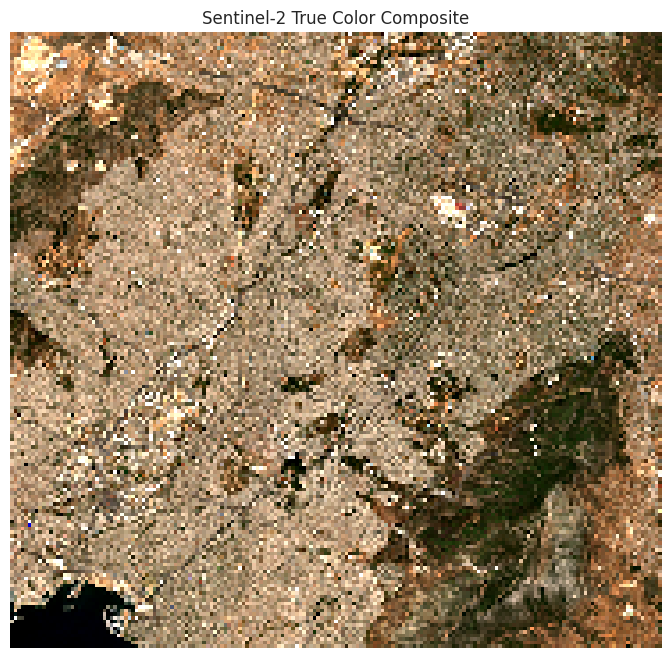

In [32]:

red = rgb["B04"].values
green = rgb["B03"].values
blue = rgb["B02"].values

rgb_array = np.stack(
    [red, green, blue],
    axis=-1
)

# Simple percentile-based color enhancement
low = np.nanpercentile(rgb_array, 2)
high = np.nanpercentile(rgb_array, 98)

rgb_display = np.clip(
    (rgb_array - low) / max(high - low, 1),
    0,
    1
)

rgb_display = np.nan_to_num(rgb_display)

plt.figure(figsize=(12, 8))
plt.imshow(rgb_display)
plt.title("Sentinel-2 True Color Composite")
plt.axis("off")

plt.savefig(
    OUTPUT / "05_true_color.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()


**Visualization 6 — False color satellite image**

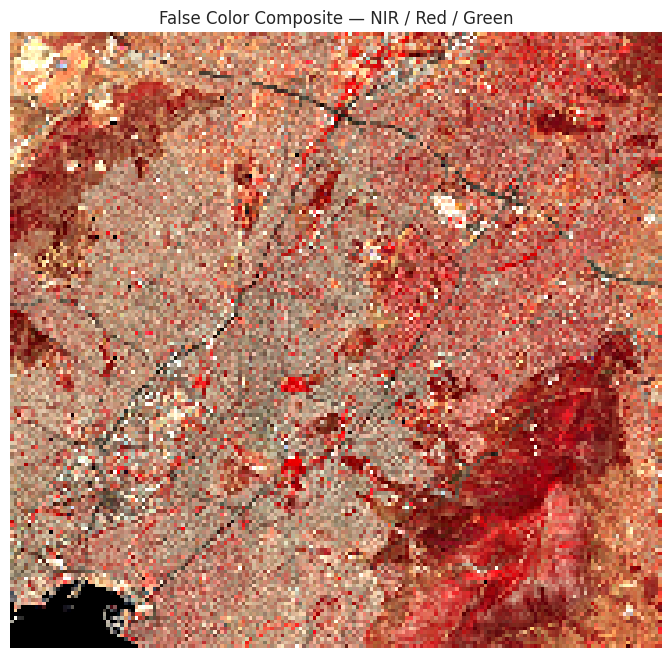

In [33]:

false_color = np.stack([
    clean["B08"].median("time").compute().values,
    clean["B04"].median("time").compute().values,
    clean["B03"].median("time").compute().values
], axis=-1)

low = np.nanpercentile(false_color, 2)
high = np.nanpercentile(false_color, 98)

false_color = np.clip(
    (false_color - low) / max(high - low, 1),
    0,
    1
)

plt.figure(figsize=(12, 8))
plt.imshow(np.nan_to_num(false_color))
plt.title("False Color Composite — NIR / Red / Green")
plt.axis("off")

plt.savefig(
    OUTPUT / "06_false_color.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()


**Visualization 7 — Water index map**

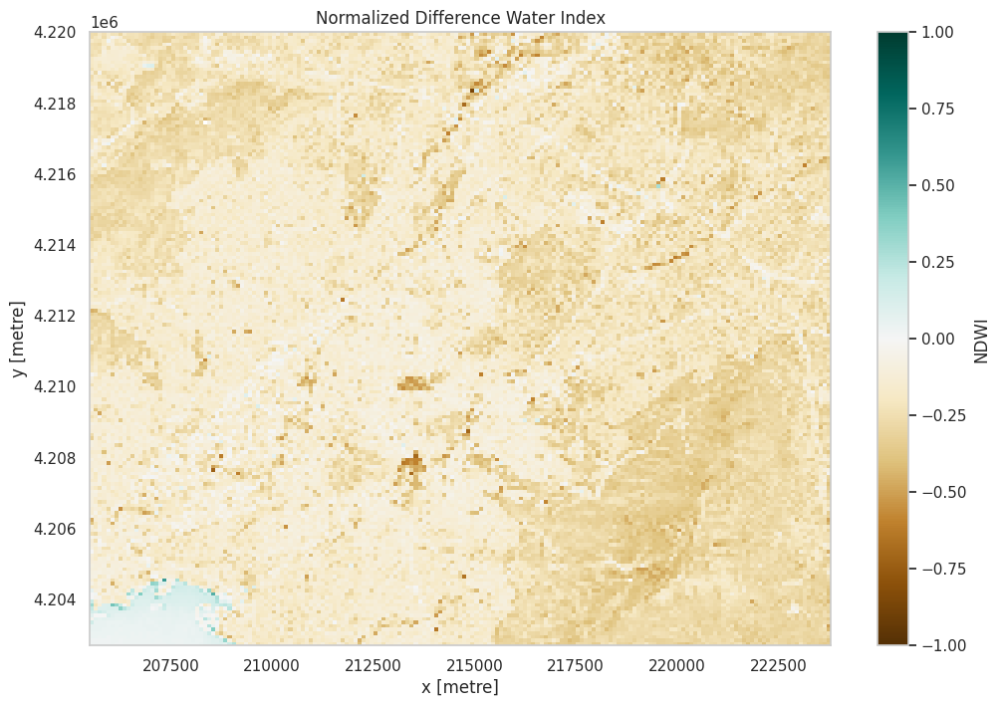

In [34]:

plt.figure(figsize=(12, 8))

composites["NDWI"].plot(
    cmap="BrBG",
    vmin=-1,
    vmax=1
)

plt.title("Normalized Difference Water Index")

plt.savefig(
    OUTPUT / "07_water_index.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()


**Visualization 8 — Vegetation change detection**

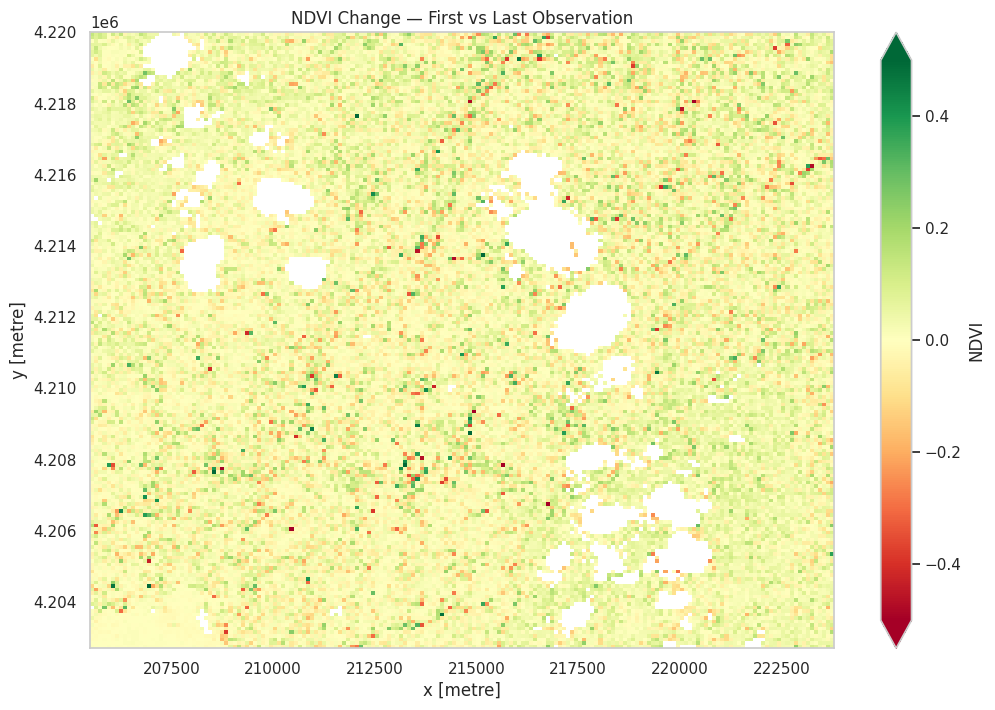

In [35]:

if indices.sizes["time"] < 2:
    raise ValueError("At least two dates are required.")

first = indices["NDVI"].isel(time=0).compute()
last = indices["NDVI"].isel(time=-1).compute()

change = last - first

plt.figure(figsize=(12, 8))

change.plot(
    cmap="RdYlGn",
    vmin=-0.5,
    vmax=0.5
)

plt.title("NDVI Change — First vs Last Observation")

plt.savefig(
    OUTPUT / "08_vegetation_change.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()


This is a two-date comparison, not a cloud-free annual trend. A more robust change analysis would compare seasonal composites from two different years.

**Step 18 — Time-series and statistical visualizations**

**Visualization 9 — NDVI time-series chart**

In [36]:

fig = px.line(
    ts,
    x="time",
    y="NDVI",
    markers=True,
    title="Athens — NDVI Time Series",
    labels={
        "time": "Satellite Observation Date",
        "NDVI": "Mean NDVI"
    }
)

fig.update_layout(
    template="plotly_white",
    height=500
)

fig.show()

fig.write_html(
    str(OUTPUT / "09_ndvi_timeseries.html")
)


**Visualization 10 — Environmental trends dashboard**

In [37]:

trend_df = ts.melt(
    id_vars="time",
    value_vars=["NDVI", "NDWI", "NDBI"],
    var_name="Index",
    value_name="Value"
)

fig = px.line(
    trend_df,
    x="time",
    y="Value",
    color="Index",
    markers=True,
    title="Satellite Environmental Index Trends"
)

fig.update_layout(
    template="plotly_dark",
    height=600
)

fig.show()

fig.write_html(
    str(OUTPUT / "10_environmental_trends.html")
)


**Visualization 11 — Seasonal anomaly heatmap**

We calculate the deviation of each observation from the mean of the available period.

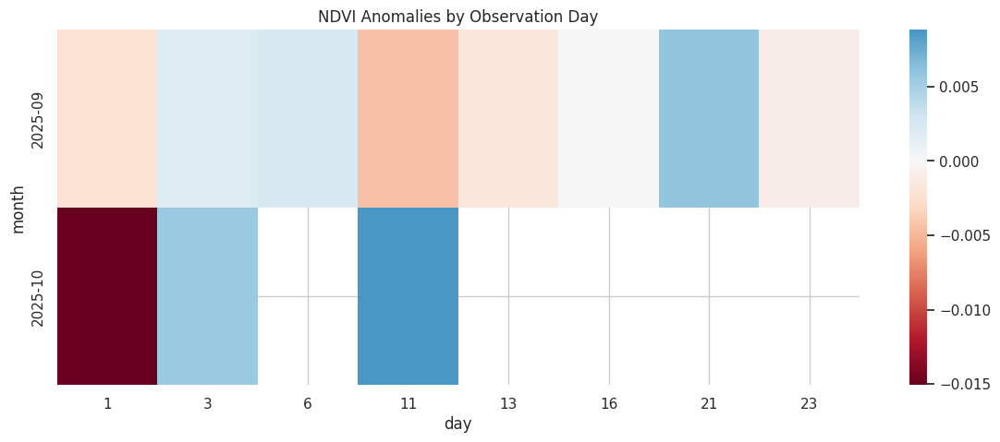

In [38]:

anomaly_df = ts.copy()

anomaly_df["NDVI_anomaly"] = (
    anomaly_df["NDVI"] -
    anomaly_df["NDVI"].mean()
)

anomaly_df["month"] = (
    anomaly_df["time"].dt.strftime("%Y-%m")
)

anomaly_df["day"] = anomaly_df["time"].dt.day

heatmap_data = anomaly_df.pivot_table(
    index="month",
    columns="day",
    values="NDVI_anomaly",
    aggfunc="mean"
)

plt.figure(figsize=(14, 5))

sns.heatmap(
    heatmap_data,
    cmap="RdBu",
    center=0,
    annot=False
)

plt.title("NDVI Anomalies by Observation Day")

plt.savefig(
    OUTPUT / "11_ndvi_anomalies.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()


These are anomalies relative to this short sample, not climatological anomalies. A true seasonal anomaly analysis would need multiple years of observations.

**Visualization 12 — NDVI distribution**

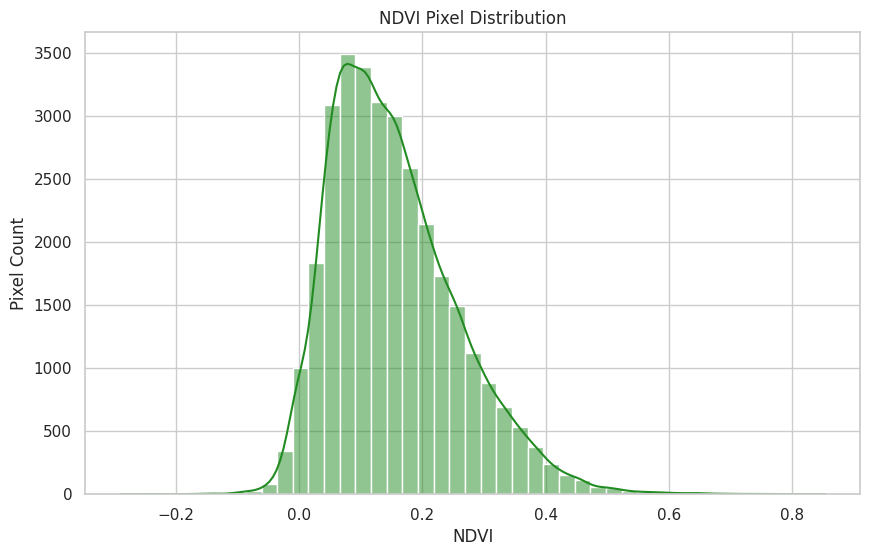

In [39]:

ndvi_values = composites["NDVI"].values.ravel()
ndvi_values = ndvi_values[np.isfinite(ndvi_values)]

plt.figure(figsize=(10, 6))

sns.histplot(
    ndvi_values,
    bins=45,
    kde=True,
    color="forestgreen"
)

plt.title("NDVI Pixel Distribution")
plt.xlabel("NDVI")
plt.ylabel("Pixel Count")

plt.savefig(
    OUTPUT / "12_ndvi_distribution.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()


**Visualization 13 — Regression analysis**

Correlation: -0.820090852086409
P-value: 0.001992340500333758


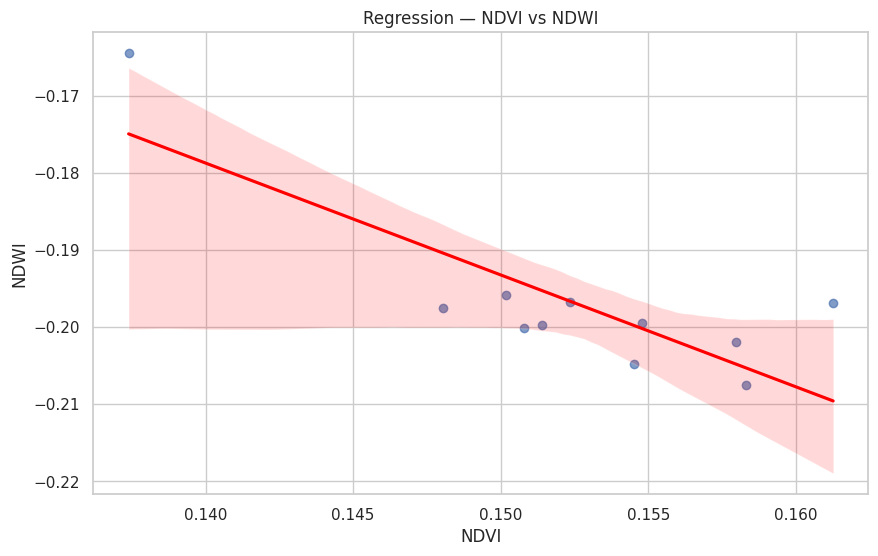

In [40]:

regression_df = ts[
    ["NDVI", "NDWI"]
].dropna()

plt.figure(figsize=(10, 6))

sns.regplot(
    data=regression_df,
    x="NDVI",
    y="NDWI",
    scatter_kws={"alpha": 0.7},
    line_kws={"color": "red"}
)

if len(regression_df) >= 3:
    result = stats.linregress(
        regression_df["NDVI"],
        regression_df["NDWI"]
    )

    print("Correlation:", result.rvalue)
    print("P-value:", result.pvalue)

plt.title("Regression — NDVI vs NDWI")

plt.savefig(
    OUTPUT / "13_regression.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()


The regression is descriptive. The indices share spectral information, so correlation alone does not establish an environmental cause.

**Visualization 14 — Multivariable pair plot**

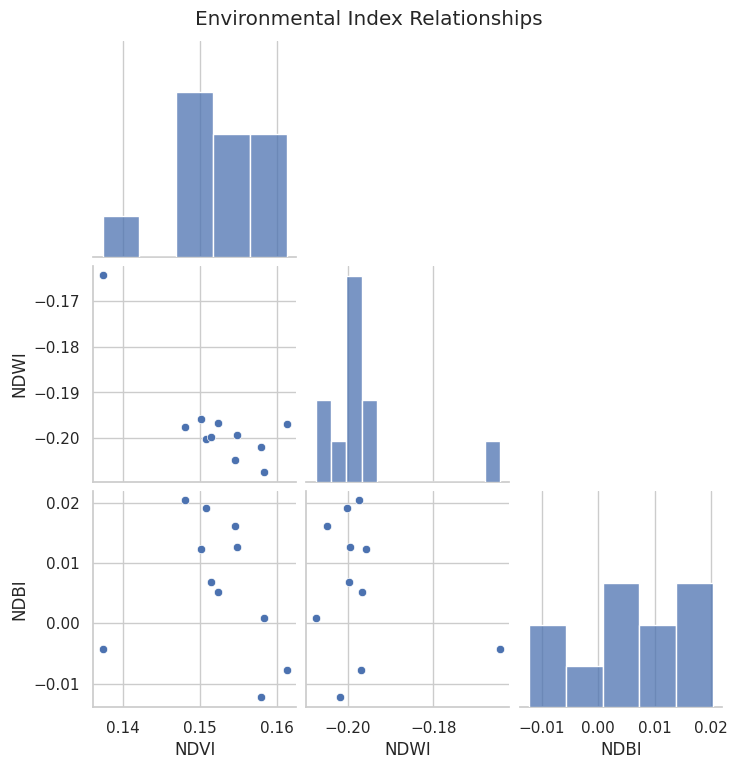

In [41]:

pair_df = ts[
    ["NDVI", "NDWI", "NDBI"]
].dropna()

g = sns.pairplot(
    pair_df,
    diag_kind="hist",
    corner=True
)

g.fig.suptitle(
    "Environmental Index Relationships",
    y=1.02
)

g.savefig(
    OUTPUT / "14_pairplot.png",
    dpi=200
)

plt.show()


**Visualization 15 — Environmental box plots**

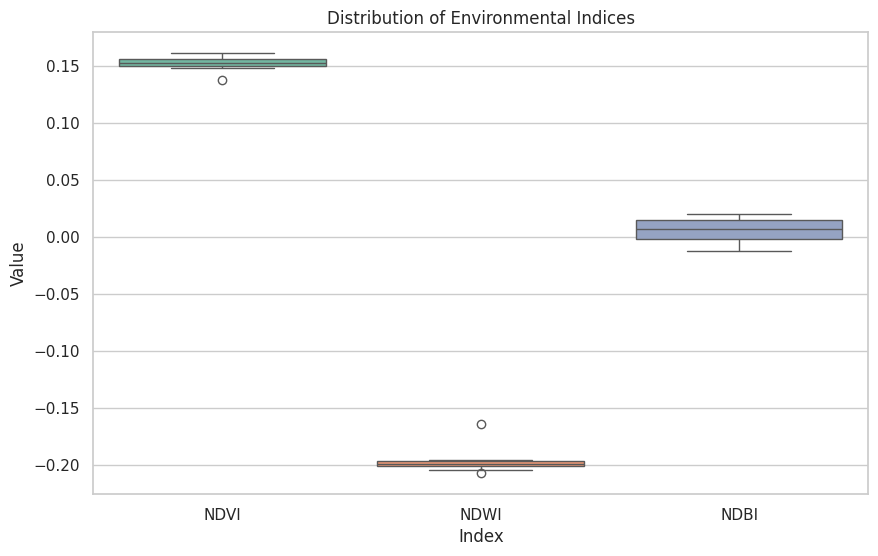

In [42]:

box_df = ts[
    ["NDVI", "NDWI", "NDBI"]
].melt(
    var_name="Index",
    value_name="Value"
)

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=box_df,
    x="Index",
    y="Value",
    hue="Index",
    palette="Set2",
    legend=False
)

plt.title("Distribution of Environmental Indices")

plt.savefig(
    OUTPUT / "15_boxplots.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()


**Visualization 16 — Principal Component Analysis (PCA)**

PCA helps explore the dominant patterns across NDVI, NDWI, and NDBI.

In [43]:

pca_df = ts[
    ["NDVI", "NDWI", "NDBI"]
].dropna().copy()

if len(pca_df) < 3:
    raise ValueError("PCA requires at least 3 valid observations.")

scaler = StandardScaler()

scaled = scaler.fit_transform(pca_df)

pca = PCA(n_components=2)

components = pca.fit_transform(scaled)

pca_result = pd.DataFrame({
    "PC1": components[:, 0],
    "PC2": components[:, 1],
    "NDVI": pca_df["NDVI"].values
})

fig = px.scatter(
    pca_result,
    x="PC1",
    y="PC2",
    color="NDVI",
    color_continuous_scale="RdYlGn",
    title="PCA — Environmental Indices"
)

fig.show()

fig.write_html(
    str(OUTPUT / "16_pca_analysis.html")
)

print(
    "Explained variance:",
    pca.explained_variance_ratio_
)


Explained variance: [0.60703576 0.37564042]


**Step 19 — Advanced 3D geospatial visualizations**

**Visualization 17 — 3D hexagon density map**

In [44]:

hex_layer = pdk.Layer(
    "HexagonLayer",
    data=geo_df,
    get_position="[longitude, latitude]",
    radius=250,
    elevation_scale=30,
    elevation_range=[0, 1000],
    extruded=True,
    pickable=True,
    coverage=0.85,
    get_fill_color="[60, 170, 90, 190]"
)

hex_deck = pdk.Deck(
    layers=[hex_layer],
    initial_view_state=view,
    map_style=None,
    tooltip={"text": "Sample count: {elevationValue}"}
)

display(hex_deck)

hex_deck.to_html(
    str(OUTPUT / "17_hexagon_3d.html"),
    notebook_display=False
)


<IPython.core.display.Javascript object>

{
  "initialViewState": {
    "bearing": 20,
    "latitude": 38.005,
    "longitude": 23.75,
    "pitch": 55,
    "zoom": 10
  },
  "layers": [
    {
      "@@type": "HexagonLayer",
      "coverage": 0.85,
      "data": [
        {
          "NDVI": 0.11345948278903961,
          "color": [
            210,
            65,
            50,
            190
          ],
          "height": 278.3648681640625,
          "latitude": 38.079417237780504,
          "longitude": 23.643093087184745
        },
        {
          "NDVI": 0.1284172534942627,
          "color": [
            210,
            65,
            50,
            190
          ],
          "height": 282.10430908203125,
          "latitude": 38.07951483584078,
          "longitude": 23.646507863610037
        },
        {
          "NDVI": 0.14707091450691223,
          "color": [
            210,
            65,
            50,
            190
          ],
          "height": 286.7677307128906,
          "latitude": 38.07961233489249,
          "longitude": 23.649922656528062
        },
        {
          "NDVI": 0.10329106450080872,
          "color": [
            210,
            65,
            50,
            190
          ],
          "height": 275.82275390625,
          "latitude": 38.07970973493416,
          "longitude": 23.65333746592217
        },
        {
          "NDVI": 0.10570427775382996,
          "color": [
            210,
            65,
            50,
            190
          ],
          "height": 276.42608642578125,
          "latitude": 38.07980703596434,
          "longitude": 23.656752291775707
        },
        {
          "NDVI": 0.261776328086853,
          "color": [
            240,
            190,
            40,
            190
          ],
          "height": 315.444091796875,
          "latitude": 38.07990423798157,
          "longitude": 23.660167134072015
        },
        {
          "NDVI": 0.1858050525188446,
          "color": [
            210,
            65,
            50,
            190
          ],
          "height": 296.4512634277344,
          "latitude": 38.080001340984396,
          "longitude": 23.663581992794434
        },
        {
          "NDVI": 0.14448630809783936,
          "color": [
            210,
            65,
            50,
            190
          ],
          "height": 286.12158203125,
          "latitude": 38.08009834497133,
          "longitude": 23.66699686792632
        },
        {
          "NDVI": 0.22924600541591644,
          "color": [
            240,
            190,
            40,
            190
          ],
          "height": 307.3114929199219,
          "latitude": 38.08019524994095,
          "longitude": 23.670411759451003
        },
        {
          "NDVI": 0.11635119467973709,
          "color": [
            210,
            65,
            50,
            190
          ],
          "height": 279.0877990722656,
          "latitude": 38.08029205589179,
          "longitude": 23.673826667351832
        },
        {
          "NDVI": 0.16255006194114685,
          "color": [
            210,
            65,
            50,
            190
          ],
          "height": 290.63751220703125,
          "latitude": 38.08038876282237,
          "longitude": 23.677241591612148
        },
        {
          "NDVI": 0.2052987813949585,
          "color": [
            240,
            190,
            40,
            190
          ],
          "height": 301.32470703125,
          "latitude": 38.08048537073129,
          "longitude": 23.680656532215295
        },
        {
          "NDVI": 0.1598113477230072,
          "color": [
            210,
            65,
            50,
            190
          ],
          "height": 289.9528503417969,
          "latitude": 38.080581879617036,
          "longitude": 23.684071489144614
        },
        {
          "NDVI": 0.08649924397468567,
          "color": [
            210,
            65,
            50,
            

<IPython.core.display.Javascript object>

**Note:** Hexagon height represents the density of sampled satellite pixels, not NDVI or physical terrain elevation. Because the sampling grid is approximately uniform, this is mainly a demonstration of the HexagonLayer.

**Visualization 18 — 3D NDVI surface**

We can create a 3D surface from the vegetation-index raster. This is a scientific visualization of NDVI values, not actual terrain elevation.

In [45]:

surface = composites["NDVI"].isel(
    x=slice(None, None, 2),
    y=slice(None, None, 2)
)

fig = go.Figure(
    data=[
        go.Surface(
            x=surface.x.values,
            y=surface.y.values,
            z=surface.values,
            colorscale="RdYlGn",
            cmin=-1,
            cmax=1,
            colorbar=dict(title="NDVI")
        )
    ]
)

fig.update_layout(
    title="3D NDVI Surface",
    scene=dict(
        xaxis_title="X coordinate",
        yaxis_title="Y coordinate",
        zaxis_title="NDVI"
    ),
    height=750
)

fig.show()

fig.write_html(
    str(OUTPUT / "18_ndvi_surface.html")
)


To produce a real 3D elevation map, we would load a Digital Elevation Model (DEM), such as Copernicus DEM, and use actual elevation values.

**Visualization 19 — Geospatial heatmap**

In [46]:

heat_df = geo_df.copy()

heat_df["weight"] = (
    (heat_df["NDVI"] + 1) / 2
).clip(0, 1)

heat_layer = pdk.Layer(
    "HeatmapLayer",
    data=heat_df,
    get_position="[longitude, latitude]",
    get_weight="weight",
    radius_pixels=35,
    intensity=1,
    threshold=0.05
)

heat_deck = pdk.Deck(
    layers=[heat_layer],
    initial_view_state=pdk.ViewState(
        latitude=38.005,
        longitude=23.75,
        zoom=10
    ),
    map_style=None
)

display(heat_deck)

heat_deck.to_html(
    str(OUTPUT / "19_geospatial_heatmap.html"),
    notebook_display=False
)


<IPython.core.display.Javascript object>

{
  "initialViewState": {
    "latitude": 38.005,
    "longitude": 23.75,
    "zoom": 10
  },
  "layers": [
    {
      "@@type": "HeatmapLayer",
      "data": [
        {
          "NDVI": 0.11345948278903961,
          "color": [
            210,
            65,
            50,
            190
          ],
          "height": 278.3648681640625,
          "latitude": 38.079417237780504,
          "longitude": 23.643093087184745,
          "weight": 0.5567297339439392
        },
        {
          "NDVI": 0.1284172534942627,
          "color": [
            210,
            65,
            50,
            190
          ],
          "height": 282.10430908203125,
          "latitude": 38.07951483584078,
          "longitude": 23.646507863610037,
          "weight": 0.5642086267471313
        },
        {
          "NDVI": 0.14707091450691223,
          "color": [
            210,
            65,
            50,
            190
          ],
          "height": 286.7677307128906,
          "latitude": 38.07961233489249,
          "longitude": 23.649922656528062,
          "weight": 0.5735354423522949
        },
        {
          "NDVI": 0.10329106450080872,
          "color": [
            210,
            65,
            50,
            190
          ],
          "height": 275.82275390625,
          "latitude": 38.07970973493416,
          "longitude": 23.65333746592217,
          "weight": 0.5516455173492432
        },
        {
          "NDVI": 0.10570427775382996,
          "color": [
            210,
            65,
            50,
            190
          ],
          "height": 276.42608642578125,
          "latitude": 38.07980703596434,
          "longitude": 23.656752291775707,
          "weight": 0.5528521537780762
        },
        {
          "NDVI": 0.261776328086853,
          "color": [
            240,
            190,
            40,
            190
          ],
          "height": 315.444091796875,
          "latitude": 38.07990423798157,
          "longitude": 23.660167134072015,
          "weight": 0.6308881640434265
        },
        {
          "NDVI": 0.1858050525188446,
          "color": [
            210,
            65,
            50,
            190
          ],
          "height": 296.4512634277344,
          "latitude": 38.080001340984396,
          "longitude": 23.663581992794434,
          "weight": 0.5929025411605835
        },
        {
          "NDVI": 0.14448630809783936,
          "color": [
            210,
            65,
            50,
            190
          ],
          "height": 286.12158203125,
          "latitude": 38.08009834497133,
          "longitude": 23.66699686792632,
          "weight": 0.5722431540489197
        },
        {
          "NDVI": 0.22924600541591644,
          "color": [
            240,
            190,
            40,
            190
          ],
          "height": 307.3114929199219,
          "latitude": 38.08019524994095,
          "longitude": 23.670411759451003,
          "weight": 0.6146230101585388
        },
        {
          "NDVI": 0.11635119467973709,
          "color": [
            210,
            65,
            50,
            190
          ],
          "height": 279.0877990722656,
          "latitude": 38.08029205589179,
          "longitude": 23.673826667351832,
          "weight": 0.5581756234169006
        },
        {
          "NDVI": 0.16255006194114685,
          "color": [
            210,
            65,
            50,
            190
          ],
          "height": 290.63751220703125,
          "latitude": 38.08038876282237,
          "longitude": 23.677241591612148,
          "weight": 0.5812750458717346
        },
        {
          "NDVI": 0.2052987813949585,
          "color": [
            240,
            190,
            40,
            190
          ],
          "height": 301.32470703125,
          "latitude": 38.08048537073129,
          "longitude": 23.680656532215295,
          "weight": 0.6026493906974792
   

<IPython.core.display.Javascript object>

This creates a weighted spatial heatmap based on NDVI, not a direct pixel-for-pixel satellite raster.

**Visualization 20 — Interactive 3D scatter plot**

In [47]:

scatter_df = geo_df.sample(
    n=min(2000, len(geo_df)),
    random_state=42
)

fig = px.scatter_3d(
    scatter_df,
    x="longitude",
    y="latitude",
    z="NDVI",
    color="NDVI",
    color_continuous_scale="RdYlGn",
    opacity=0.7,
    title="3D Geospatial NDVI Distribution"
)

fig.update_layout(
    height=750,
    template="plotly_dark"
)

fig.show()

fig.write_html(
    str(OUTPUT / "20_geospatial_scatter.html")
)


**Step 21 — Export all visualizations**

**Export interactive Plotly charts as PNG**

Install Kaleido:

In [48]:

%pip install -q kaleido


Then export the interactive Plotly charts to PNG where supported by your Colab environment:

In [49]:

# Example: export the last Plotly figure
try:
    fig.write_image(
        str(OUTPUT / "20_geospatial_scatter.png"),
        width=1400,
        height=900,
        scale=2
    )
    print("PNG export successful")
except Exception as exc:
    print("Static export unavailable:", exc)
    print("Interactive HTML remains available.")


Static export unavailable: 
Image export using the "kaleido" engine requires the kaleido package,
which can be installed using pip:
    $ pip install -U kaleido

Interactive HTML remains available.


Kaleido's current versions may require Chrome or Chromium. HTML export works independently of that requirement.

**Create a ZIP with all generated files**

In [50]:

import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "/content/SatEO_Analytics_Results",
    "zip",
    OUTPUT
)

print("Created:", zip_path)
print("Files generated:")

for file in sorted(OUTPUT.iterdir()):
    print("-", file.name)

files.download(zip_path)


Created: /content/SatEO_Analytics_Results.zip
Files generated:
- 01_vegetation_health.png
- 02_environment_dashboard.html
- 03_correlation_heatmap.png
- 04_geospatial_3d.html
- 05_true_color.png
- 06_false_color.png
- 07_water_index.png
- 08_vegetation_change.png
- 09_ndvi_timeseries.html
- 10_environmental_trends.html
- 11_ndvi_anomalies.png
- 12_ndvi_distribution.png
- 13_regression.png
- 14_pairplot.png
- 15_boxplots.png
- 16_pca_analysis.html
- 17_hexagon_3d.html
- 18_ndvi_surface.html
- 19_geospatial_heatmap.html
- 20_geospatial_scatter.html
- correlation_heatmap.png
- environmental_dashboard.html
- environmental_timeseries.csv
- geospatial_3d_map.html
- geospatial_grid.csv
- vegetation_health.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>